# Izaz Khan | LAB 01
###Image Acquisition and Basic Image Processing using OpenCV


| Field | Details |
|---|---|
| Reg. No. |B23F0001AI029 |
| Section |AI green |
| Date |11/10/2026 |

In [52]:
import os
os.makedirs("Lab01/input_images", exist_ok=True)
os.makedirs("Lab01/output_images", exist_ok=True)
print("Folders ready:", os.listdir("Lab01"))

Folders ready: ['input_images', 'output_images']


### Task 1: Environment Setup and OpenCV Verification


In [53]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)

sample = np.zeros((5, 5), dtype=np.uint8)
print(sample)
print("Shape:", sample.shape)
print("Data type:", sample.dtype)
print("Dimensions:", sample.ndim)

OpenCV Version: 5.0.0
NumPy Version: 2.1.3
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
Shape: (5, 5)
Data type: uint8
Dimensions: 2


#Q5. Why are NumPy arrays important when working with images in OpenCV?
OpenCV stores every image as a NumPy array, so each pixel is a numeric value that can be read and changed directly. Array indexing and slicing let us access single pixels or whole regions, and vectorized operations let us compute statistics such as the mean, minimum and maximum over millions of pixels quickly without loops. NumPy arrays also work with Matplotlib and with machine learning libraries.

## Task 02

In [63]:
import shutil
from google.colab import files

uploaded = files.upload()

for name in uploaded.keys():
    shutil.move(name, f"Lab01/input_images/{name}")

print(os.listdir("Lab01/input_images"))

Saving car.jpeg to car.jpeg
Saving Everyday.jpeg to Everyday.jpeg
Saving indoor.jpeg to indoor.jpeg
Saving outdoor.jpeg to outdoor.jpeg
Saving person.jpeg to person.jpeg
['outdoor.jpeg', 'car.jpeg', 'person.jpeg', 'Everyday.jpeg', 'indoor.jpeg', '2.jpeg', '1.jpeg']


In [64]:
import pandas as pd

records = [
    # (filename, acquisition source, subject)
    ("person.jpg",    "Phone camera (taken by me)", "Person / pet"),
    ("building.jpg",  "Phone camera (taken by me)", "Indoor scene"),
    ("landscape.jpg", "Downloaded from Unsplash",   "Outdoor landscape"),
    ("vehicle.jpg",   "Downloaded from Pexels",     "Car"),
    ("object.jpg",    "Phone camera (taken by me)", "Everyday object"),
]

table = pd.DataFrame(
    [(f"Image {i+1}", f, src, f.split(".")[-1].upper(), sub)
     for i, (f, src, sub) in enumerate(records)],
    columns=["Image", "File Name", "Acquisition Source", "Format", "Subject"]
)
display(table)

,Image,File Name,Acquisition Source,Format,Subject
0,Image 1,person.jpg,Phone camera (taken by me),JPG,Person / pet
1,Image 2,building.jpg,Phone camera (taken by me),JPG,Indoor scene
2,Image 3,landscape.jpg,Downloaded from Unsplash,JPG,Outdoor landscape
3,Image 4,vehicle.jpg,Downloaded from Pexels,JPG,Car
4,Image 5,object.jpg,Phone camera (taken by me),JPG,Everyday object


In real computer vision systems, images are acquired by sensors that convert light into digital signals, most commonly CCD or CMOS image sensors in cameras. Industrial systems use fixed cameras with controlled lighting to inspect products on a production line, while mobile phones, drones and dashcams capture images in uncontrolled environments. Specialized sources such as medical scanners (X-ray, CT, MRI), satellites, thermal cameras and LiDAR provide imagery beyond visible light. Images can also come from existing datasets and online repositories, which is how most models are trained. The acquisition method strongly affects resolution, noise, lighting and color accuracy, which in turn affect every later processing step.

### Q11. Four devices or sources used for image acquisition

Digital cameras and smartphone cameras (CMOS/CCD sensors)
Medical imaging devices such as X-ray, CT and MRI scanners
Satellites and drones (remote sensing and aerial imagery)
Surveillance/CCTV and industrial inspection cameras
Also valid: thermal cameras, LiDAR/depth sensors such as Kinect, and scanners

# Task 3: Reading and Validating Images with OpenCV

In [65]:
import os
print("Current folder:", os.getcwd())
print("input_images:", os.listdir("Lab01/input_images") if os.path.exists("Lab01/input_images") else "FOLDER MISSING")
print("Root files:", os.listdir("."))

Current folder: /content
input_images: ['outdoor.jpeg', 'car.jpeg', 'person.jpeg', 'Everyday.jpeg', 'indoor.jpeg', '2.jpeg', '1.jpeg']
Root files: ['.config', 'Lab01', 'Lab01_Output.zip', 'Lab01_Output', 'sample_data']


In [66]:
os.makedirs("Lab01/input_images", exist_ok=True)
os.makedirs("Lab01/output_images", exist_ok=True)

import shutil
from google.colab import files
uploaded = files.upload()
for name in uploaded.keys():
    shutil.move(name, f"Lab01/input_images/{name}")
print(os.listdir("Lab01/input_images"))

Saving car.jpeg to car.jpeg
Saving Everyday.jpeg to Everyday.jpeg
Saving indoor.jpeg to indoor.jpeg
Saving outdoor.jpeg to outdoor.jpeg
Saving person.jpeg to person.jpeg
['outdoor.jpeg', 'car.jpeg', 'person.jpeg', 'Everyday.jpeg', 'indoor.jpeg', '2.jpeg', '1.jpeg']


In [67]:
filenames = sorted(os.listdir("Lab01/input_images"))
print(filenames)

['1.jpeg', '2.jpeg', 'Everyday.jpeg', 'car.jpeg', 'indoor.jpeg', 'outdoor.jpeg', 'person.jpeg']


In [68]:
for name in os.listdir("."):
    if name.lower().endswith((".jpg", ".jpeg", ".png")):
        shutil.move(name, f"Lab01/input_images/{name}")

In [69]:
import cv2
import os

# Initialize the images dictionary and load files from the folder
images = {}
input_folder = "Lab01/input_images"
if os.path.exists(input_folder):
    for filename in os.listdir(input_folder):
        filepath = os.path.join(input_folder, filename)
        # Read image using OpenCV
        img = cv2.imread(filepath)
        if img is not None:
            images[filename] = img

# Select the first three loaded images
selected = list(images.keys())[:3]
rows = []

for i, name in enumerate(selected, start=1):
    img = images[name]
    height, width, channels = img.shape
    print(f"--- Image {i}: {name} ---")
    print("Shape:", img.shape)
    print("Height:", height)
    print("Width:", width)
    print("Channels:", channels)
    print("Total elements:", img.size)
    print("Data type:", img.dtype)
    print()
    rows.append((f"Image {i} ({name})", height, width, channels, img.size, str(img.dtype)))

--- Image 1: outdoor.jpeg ---
Shape: (678, 452, 3)
Height: 678
Width: 452
Channels: 3
Total elements: 919368
Data type: uint8

--- Image 2: car.jpeg ---
Shape: (452, 678, 3)
Height: 452
Width: 678
Channels: 3
Total elements: 919368
Data type: uint8

--- Image 3: person.jpeg ---
Shape: (4032, 3024, 3)
Height: 4032
Width: 3024
Channels: 3
Total elements: 36578304
Data type: uint8



In [70]:
import pandas as pd

df = pd.DataFrame(rows, columns=["Image", "Height", "Width", "Channels", "Elements", "Data Type"])

if not df.empty:
    df["Resolution (pixels)"] = df["Height"] * df["Width"]
    display(df)
    best = df.loc[df["Resolution (pixels)"].idxmax()]
    print("Highest resolution image:", best["Image"])
    print("Resolution:", best["Width"], "x", best["Height"], "=", best["Resolution (pixels)"], "pixels")
else:
    print("No images found. Please ensure that the 'images' dictionary is populated with loaded images.")

,Image,Height,Width,Channels,Elements,Data Type,Resolution (pixels)
0,Image 1 (outdoor.jpeg),678,452,3,919368,uint8,306456
1,Image 2 (car.jpeg),452,678,3,919368,uint8,306456
2,Image 3 (person.jpeg),4032,3024,3,36578304,uint8,12192768


Highest resolution image: Image 3 (person.jpeg)
Resolution: 3024 x 4032 = 12192768 pixels


## Q20. How do width and height determine image resolution?

Resolution is the number of pixels in the image, which is width × height. For example, a 1920×1080 image has 2,073,600 pixels (about 2 megapixels). More pixels means more detail can be stored, but also more memory and processing time. Height and width also set the aspect ratio of the image.

## Q21. Why is uint8 commonly used for standard digital images?

An unsigned 8-bit integer stores values from 0 to 255, which gives 256 intensity levels per channel. That is enough for the human eye to see smooth tones, and it uses only one byte per value, so images stay compact. It also matches how most cameras, displays and common formats such as JPEG and PNG store pixel data. A color image therefore needs three bytes per pixel, which is manageable in memory.

# **Task 5: Displaying Images with Matplotlib**

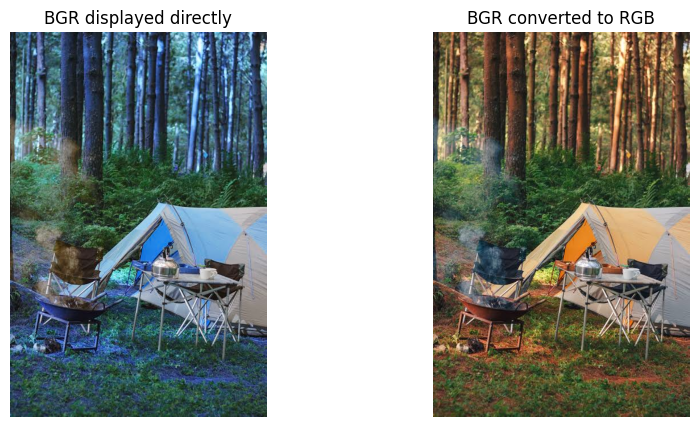

In [71]:
img = images[list(images.keys())[0]]

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("BGR displayed directly")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_rgb)
plt.title("BGR converted to RGB")
plt.axis("off")

plt.show()

The directly displayed image has incorrect colors, with red and blue channels swapped, while the converted RGB image shows natural colors matching the original scene.

## Q25. Why do colors sometimes look incorrect when an OpenCV image is directly displayed in Matplotlib?

OpenCV loads color images with channels in BGR order (Blue, Green, Red), but Matplotlib's imshow() assumes RGB order. When a BGR array is passed directly, Matplotlib treats the blue channel as red and the red channel as blue, so those two colors are swapped while green stays the same. Converting with cv2.cvtColor(img, cv2.COLOR_BGR2RGB) reorders the channels so the colors display correctly.

# **Task 6: Color to Grayscale Conversion**

--- outdoor.jpeg ---
Color     -> Shape: (678, 452, 3) | Dimensions: 3 | dtype: uint8 | Elements: 919368
Grayscale -> Shape: (678, 452) | Dimensions: 2 | dtype: uint8 | Elements: 306456

--- car.jpeg ---
Color     -> Shape: (452, 678, 3) | Dimensions: 3 | dtype: uint8 | Elements: 919368
Grayscale -> Shape: (452, 678) | Dimensions: 2 | dtype: uint8 | Elements: 306456

--- person.jpeg ---
Color     -> Shape: (4032, 3024, 3) | Dimensions: 3 | dtype: uint8 | Elements: 36578304
Grayscale -> Shape: (4032, 3024) | Dimensions: 2 | dtype: uint8 | Elements: 12192768



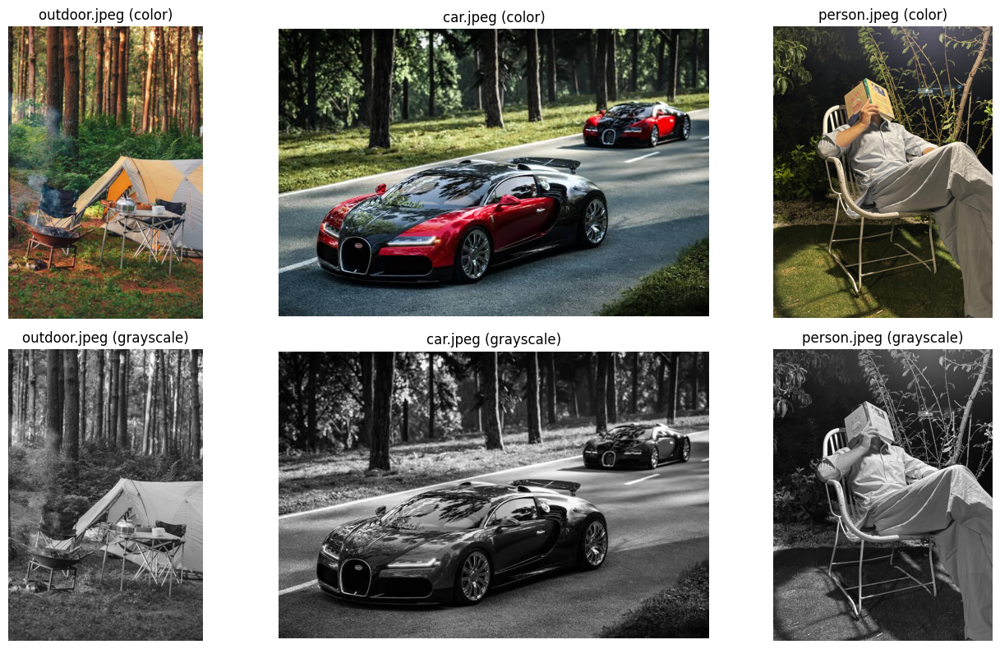

In [72]:
selected = list(images.keys())[:3]

plt.figure(figsize=(15, 8))

for i, name in enumerate(selected):
    img = images[name]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Color (converted to RGB for correct display)
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{name} (color)")
    plt.axis("off")

    # Grayscale
    plt.subplot(2, 3, i + 4)
    plt.imshow(gray, cmap="gray")
    plt.title(f"{name} (grayscale)")
    plt.axis("off")

    print(f"--- {name} ---")
    print("Color     -> Shape:", img.shape, "| Dimensions:", img.ndim, "| dtype:", img.dtype, "| Elements:", img.size)
    print("Grayscale -> Shape:", gray.shape, "| Dimensions:", gray.ndim, "| dtype:", gray.dtype, "| Elements:", gray.size)
    print()

plt.tight_layout()
plt.show()

In [73]:
img = images[selected[0]]
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

comparison = pd.DataFrame({
    "Property": ["Dimensions", "Channels", "Data type", "Number of elements"],
    "Color Image": [img.ndim, img.shape[2], str(img.dtype), img.size],
    "Grayscale Image": [gray.ndim, 1, str(gray.dtype), gray.size],
})
display(comparison)

,Property,Color Image,Grayscale Image
0,Dimensions,3,2
1,Channels,3,1
2,Data type,uint8,uint8
3,Number of elements,919368,306456


## Q29. Why can grayscale images require less memory than color images?

A color image stores three values per pixel (B, G, R), while a grayscale image stores one intensity value per pixel. With the same dimensions and uint8 data type, the grayscale array has one third as many elements, so it uses about one third of the memory (roughly a 66.7% reduction).

# **Task 7: Separating Blue, Green, and Red Channels**

Selected image: outdoor.jpeg
Blue mean : 67.62975108987914
Green mean: 93.91909442138513
Red mean  : 103.8297504372569


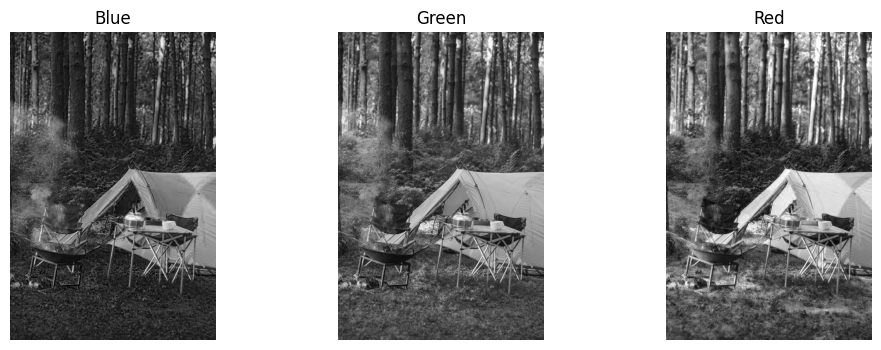

In [74]:
name = list(images.keys())[0]   # choose the image you want to analyze
img = images[name]
print("Selected image:", name)

b, g, r = cv2.split(img)

print("Blue mean :", np.mean(b))
print("Green mean:", np.mean(g))
print("Red mean  :", np.mean(r))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(b, cmap="gray"); plt.title("Blue");  plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(g, cmap="gray"); plt.title("Green"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(r, cmap="gray"); plt.title("Red");   plt.axis("off")
plt.show()

In [75]:
means = {"Blue": np.mean(b), "Green": np.mean(g), "Red": np.mean(r)}
print("Highest average channel:", max(means, key=means.get))

Highest average channel: Red


How to read the channel images
In each grayscale map, bright areas mean that color is strong in that part of the image. For example, a blue sky looks bright in the Blue map and dark in the Red map.

## Q33. Which channel has the highest average intensity?

This depends on your image, so use your printed output. Write the answer like this, filling in your numbers:

For [image name], the [Blue/Green/Red] channel has the highest mean intensity ([value]), compared with [value] and [value] for the other two channels.

## Q34. What might a large mean value in one channel indicate about the image?

It suggests that color dominates the image. For example, a high blue mean points to scenes with sky, water or blue objects, a high green mean to vegetation, and a high red mean to warm lighting, sunsets, skin tones or red objects. It can also indicate a color cast caused by lighting or white balance, such as a yellowish or reddish tint from indoor bulbs. Very high values in all three channels together indicate a bright image overall.

#**Task 8: Reconstructing an Image from Channels**

Maximum Difference: 0
Reconstruction was EXACT (lossless).


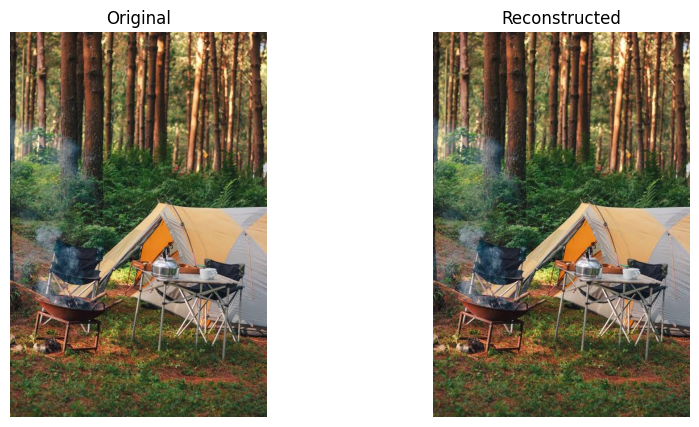

In [76]:
reconstructed = cv2.merge([b, g, r])

# int16 avoids uint8 wraparound when subtracting
difference = np.abs(img.astype(np.int16) - reconstructed.astype(np.int16))
max_diff = difference.max()
print("Maximum Difference:", max_diff)

if max_diff == 0:
    print("Reconstruction was EXACT (lossless).")
else:
    print("Reconstruction was NOT exact.")

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(reconstructed, cv2.COLOR_BGR2RGB))
plt.title("Reconstructed")
plt.axis("off")
plt.show()

The maximum absolute pixel difference between the original and reconstructed images was 0, so the reconstruction was exact. Splitting and merging channels only rearranges the existing pixel values and does not change them.

## Q38. What is the purpose of cv2.merge()?
cv2.merge() combines separate single-channel arrays (such as B, G and R) into one multi-channel color image. It is the inverse of cv2.split(). It is used after processing channels individually, for example to modify one channel and rebuild the image, or to create a custom color image from separate channels. The channels must have the same height and width, and the order passed in must match the intended BGR order.

## Q39. What maximum difference would you expect if reconstruction is perfect?
Zero. If every pixel in the reconstructed image equals the original, the absolute difference is 0 everywhere, so the maximum is also 0.

#**Task 9: Accessing Individual Pixel Values**

In [77]:
img = images[list(images.keys())[0]]
h, w = img.shape[:2]
print("Image size (H x W):", h, "x", w)

fractions = [(0.1, 0.1), (0.1, 0.5), (0.1, 0.9), (0.3, 0.3), (0.3, 0.7),
             (0.5, 0.5), (0.7, 0.3), (0.7, 0.7), (0.9, 0.2), (0.9, 0.8)]

pixel_rows = []
for fy, fx in fractions:
    row, col = int(fy * h), int(fx * w)
    blue, green, red = img[row, col]
    pixel_rows.append((row, col, int(blue), int(green), int(red)))

pixel_df = pd.DataFrame(pixel_rows, columns=["Row", "Column", "Blue", "Green", "Red"])
display(pixel_df)

# Single-pixel example from the manual
row, col = 100, 150
pixel = img[row, col]
print("Pixel BGR:", pixel)
print("Blue:", img[row, col, 0])
print("Green:", img[row, col, 1])
print("Red:", img[row, col, 2])

Image size (H x W): 678 x 452


,Row,Column,Blue,Green,Red
0,67,45,15,31,48
1,67,226,107,165,230
2,67,406,41,77,113
3,203,135,42,50,90
4,203,316,117,158,227
5,339,226,148,187,195
6,474,135,118,118,148
7,474,316,144,158,180
8,610,90,77,107,126
9,610,361,64,91,165


Pixel BGR: [39 47 60]
Blue: 39
Green: 47
Red: 60


The manual's example uses [100, 150], which only works if the image is at least 101 pixels tall and 151 wide. That is true for normal photos.

In [78]:
total = img.astype(np.int32).sum(axis=2)
bch, gch, rch = img[:,:,0].astype(int), img[:,:,1].astype(int), img[:,:,2].astype(int)

targets = {
    "Dark":     np.argmin(total),
    "Bright":   np.argmax(total),
    "Reddish":  np.argmax(rch - (bch + gch) / 2),
    "Greenish": np.argmax(gch - (bch + rch) / 2),
    "Bluish":   np.argmax(bch - (gch + rch) / 2),
}

for label, idx in targets.items():
    row, col = np.unravel_index(idx, total.shape)
    print(f"{label:9s} -> (row {row}, col {col}) BGR = {img[row, col]}")

Dark      -> (row 462, col 268) BGR = [0 0 0]
Bright    -> (row 410, col 263) BGR = [255 254 255]
Reddish   -> (row 510, col 348) BGR = [  4 105 244]
Greenish  -> (row 422, col 214) BGR = [ 98 224 188]
Bluish    -> (row 401, col 156) BGR = [94 55 40]


## Q44. What does a BGR value close to [0, 0, 0] represent?

Black, or a very dark pixel. All three channels have almost no intensity, so almost no light is represented at that location.

##Q45. What does a BGR value close to [255, 255, 255] represent?

White, or a very bright pixel. All three channels are at maximum intensity. Values near this are common in bright lights, white surfaces and overexposed areas.

Say "next" for Task 10.

#**Task 10: Modifying Pixels and Rectangular Regions**

The manual's example blocks use coordinates up to column 370 and row 150, so your image needs to be at least about 150 pixels tall and 370 wide. The code below checks that and scales the blocks to the image size if needed.

Image size (H x W): 678 x 452
Original pixel at (100,150): [39 47 60]
Modified pixel at (100,150): [  0 255   0]


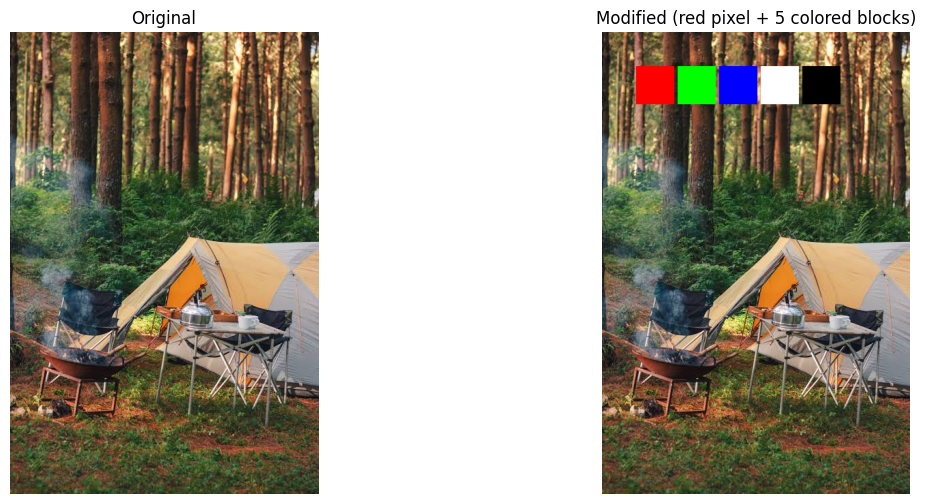

In [79]:
img = images[list(images.keys())[0]]
h, w = img.shape[:2]
print("Image size (H x W):", h, "x", w)

# Block size and spacing scaled to the image
bs = min(100, h // 4, w // 8)       # block size
gap = bs // 10
y1, y2 = 50, 50 + bs
x0 = 50

# Copy first so the original stays untouched
modified = img.copy()

# 1. Single pixel set to red (BGR)
modified[100, 150] = [0, 0, 255]

# 2. Colored blocks, all in the same copy, at different locations
modified[y1:y2, x0:x0 + bs] = [0, 0, 255]                              # Red
modified[y1:y2, x0 + (bs + gap):x0 + 2*bs + gap] = [0, 255, 0]        # Green
modified[y1:y2, x0 + 2*(bs + gap):x0 + 3*bs + 2*gap] = [255, 0, 0]    # Blue
modified[y1:y2, x0 + 3*(bs + gap):x0 + 4*bs + 3*gap] = [255, 255, 255] # White
modified[y1:y2, x0 + 4*(bs + gap):x0 + 5*bs + 4*gap] = [0, 0, 0]       # Black

# Confirm the original was not changed
print("Original pixel at (100,150):", img[100, 150])
print("Modified pixel at (100,150):", modified[100, 150])

# Display
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(modified, cv2.COLOR_BGR2RGB))
plt.title("Modified (red pixel + 5 colored blocks)")
plt.axis("off")
plt.show()

In [80]:
modified[95:105, 145:155] = [0, 0, 255]   # 10x10 red patch around the pixel

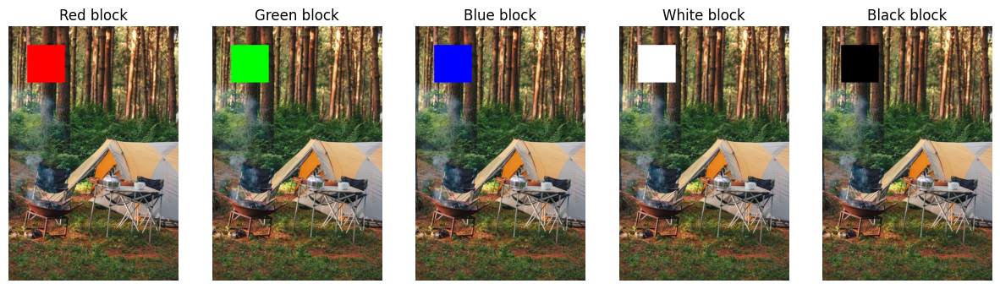

In [81]:
colors = {"Red": [0,0,255], "Green": [0,255,0], "Blue": [255,0,0], "White": [255,255,255], "Black": [0,0,0]}
plt.figure(figsize=(15, 4))
for i, (cname, bgr) in enumerate(colors.items(), start=1):
    c = img.copy()
    c[50:150, 50:150] = bgr
    plt.subplot(1, 5, i)
    plt.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
    plt.title(f"{cname} block")
    plt.axis("off")
plt.show()

##Q50. Why is it useful to call img.copy() before changing pixels?

NumPy assignment such as modified = img creates a reference to the same array and not a new image, so changing modified would also change img. img.copy() creates an independent array. This preserves the original image for later comparison and further tasks, and prevents earlier edits from affecting the results of later experiments.

#**Task 11: Region of Interest (ROI) Extraction**

Choose an image with several distinct areas, such as a landscape (sky, ground, objects) or a street scene. Set the ROI coordinates to match what you can actually see. The default values below are placed as fractions of the image (top, middle, bottom), so they run on any image, but you should adjust them so each ROI covers something meaningful, such as the sky, a car, a face or a building.

In [82]:
name = list(images.keys())[0]  # Dynamically select the first available loaded image, e.g., '1.jpeg'
img = images[name]
h, w = img.shape[:2]
print(name, "-> size (H x W):", h, "x", w)

# ROIs as (y1, y2, x1, x2, description) -- adjust to real objects in your image
rois_def = [
    (0,          int(0.30*h), 0,          w,          "Top region (e.g., sky)"),
    (int(0.35*h), int(0.70*h), int(0.25*w), int(0.75*w), "Center region (main subject)"),
    (int(0.70*h), h,          0,          int(0.50*w), "Bottom-left region (e.g., ground)"),
]

rois = []
roi_rows = []
for i, (y1, y2, x1, x2, desc) in enumerate(rois_def, start=1):
    roi = img[y1:y2, x1:x2]
    rois.append(roi)
    rh, rw = roi.shape[:2]
    mean_int = np.mean(roi)
    print(f"ROI {i}: shape = {roi.shape}, mean intensity = {mean_int:.2f}")
    roi_rows.append((f"ROI {i}", rh, rw, round(mean_int, 2), desc))

roi_df = pd.DataFrame(roi_rows, columns=["ROI", "Height", "Width", "Mean Intensity", "Description"])
display(roi_df)

outdoor.jpeg -> size (H x W): 678 x 452
ROI 1: shape = (203, 452, 3), mean intensity = 88.17
ROI 2: shape = (237, 226, 3), mean intensity = 96.36
ROI 3: shape = (204, 226, 3), mean intensity = 70.60


,ROI,Height,Width,Mean Intensity,Description
0,ROI 1,203,452,88.17,"Top region (e.g., sky)"
1,ROI 2,237,226,96.36,Center region (main subject)
2,ROI 3,204,226,70.60,"Bottom-left region (e.g., ground)"


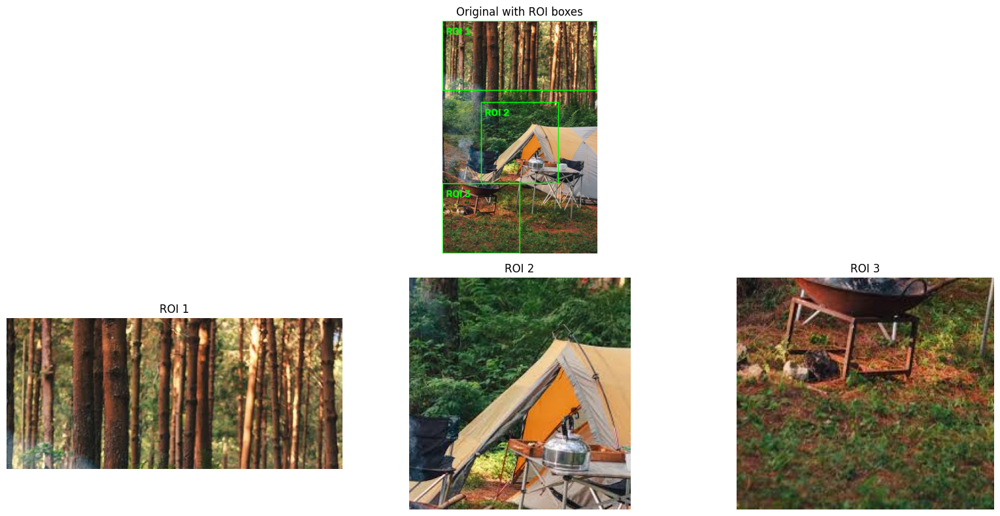

In [83]:
# Define the image height and width
h, w = img.shape[:2]

# Redefine the ROI boundaries dynamically based on the current image size
rois_def = [
    (0,          int(0.30*h), 0,          w,          "Top region (e.g., sky)"),
    (int(0.35*h), int(0.70*h), int(0.25*w), int(0.75*w), "Center region (main subject)"),
    (int(0.70*h), h,          0,          int(0.50*w), "Bottom-left region (e.g., ground)"),
]

# Re-extract the ROIs so they exist for plotting
rois = []
for y1, y2, x1, x2, desc in rois_def:
    rois.append(img[y1:y2, x1:x2])

# Draw the ROI boxes on a copy so the original stays clean
boxed = img.copy()
for i, (y1, y2, x1, x2, desc) in enumerate(rois_def, start=1):
    cv2.rectangle(boxed, (x1, y1), (x2 - 1, y2 - 1), (0, 255, 0), max(2, w // 300))
    cv2.putText(boxed, f"ROI {i}", (x1 + 10, y1 + 40), cv2.FONT_HERSHEY_SIMPLEX,
                max(1, w / 1000), (0, 255, 0), max(2, w // 400))

plt.figure(figsize=(16, 8))
plt.subplot(2, 3, (1, 3))
plt.imshow(cv2.cvtColor(boxed, cv2.COLOR_BGR2RGB))
plt.title("Original with ROI boxes")
plt.axis("off")

for i, roi in enumerate(rois, start=1):
    plt.subplot(2, 3, 3 + i)
    plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
    plt.title(f"ROI {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Q55. What is a Region of Interest?

A Region of Interest (ROI) is a selected sub-area of an image, usually rectangular, that contains the part we want to analyze or process, such as a face, a license plate or a tumor. In OpenCV and NumPy it is extracted with array slicing, img[y1:y2, x1:x2].

## Q56. Why are ROIs useful in computer vision?
Processing only the relevant region reduces computation time and memory use, because the algorithm does not scan the entire image. It also improves accuracy, because irrelevant background cannot interfere with the analysis. ROIs are used to crop faces for recognition, isolate license plates for reading, focus on lanes in autonomous driving, and measure properties of a specific object separately from the rest of the scene.

#**Task 12: Copying and Replacing an ROI**

Image size (H x W): 678 x 452 | ROI size: 90 x 90
Example 1: source (67,45) -> destination (406,271), ROI shape (90, 90, 3)
Example 2: source (271,180) -> destination (67,293), ROI shape (90, 90, 3)
Example 3: source (440,45) -> destination (237,45), ROI shape (90, 90, 3)


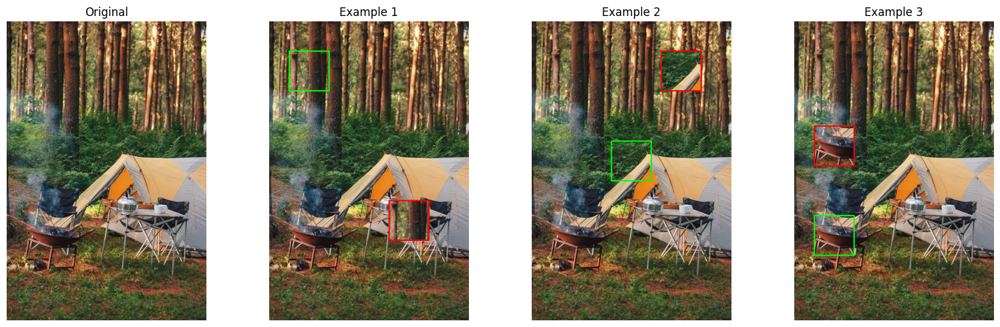

In [84]:
name = list(images.keys())[0]     # any loaded image
img = images[name]
h, w = img.shape[:2]
s = min(h, w) // 5                # ROI side length (square)
print("Image size (H x W):", h, "x", w, "| ROI size:", s, "x", s)

# (source_y, source_x, dest_y, dest_x) -- top-left corners
experiments = [
    (int(0.10*h), int(0.10*w), int(0.60*h), int(0.60*w)),   # Example 1: top-left -> bottom-right
    (int(0.40*h), int(0.40*w), int(0.10*h), int(0.65*w)),   # Example 2: center -> top-right
    (int(0.65*h), int(0.10*w), int(0.35*h), int(0.10*w)),   # Example 3: bottom-left -> middle-left
]

plt.figure(figsize=(16, 5))
plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

for i, (sy, sx, dy, dx) in enumerate(experiments, start=1):
    roi = img[sy:sy+s, sx:sx+s].copy()      # extract with .copy()
    result = img.copy()
    result[dy:dy+s, dx:dx+s] = roi          # same dimensions: s x s

    # Outline source (green) and destination (red) so the paste is easy to see
    cv2.rectangle(result, (sx, sy), (sx+s, sy+s), (0, 255, 0), max(2, w // 400))
    cv2.rectangle(result, (dx, dy), (dx+s, dy+s), (0, 0, 255), max(2, w // 400))

    print(f"Example {i}: source ({sy},{sx}) -> destination ({dy},{dx}), ROI shape {roi.shape}")

    plt.subplot(1, 4, i + 1)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"Example {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [85]:
try:
    roi = img[50:150, 50:150].copy()           # 100 x 100
    bad = img.copy()
    bad[200:350, 200:300] = roi                # destination is 150 x 100
except ValueError as e:
    print("Error:", e)

Error: could not broadcast input array from shape (100,100,3) into shape (150,100,3)


## Q60. What happens if the source and destination regions have different dimensions?
NumPy raises a ValueError saying the input array cannot be broadcast into the destination shape, and the assignment is not performed. The ROI and the target slice must have identical height and width, and the same number of channels. If the sizes differ, you must either resize the ROI (for example with cv2.resize()) or adjust the destination slice so that both shapes match.

##Q61. One real computer vision application where ROI manipulation could be useful
Face anonymization in video and street imagery. A detector locates each face, which is then extracted as an ROI and replaced or overwritten with a blurred or solid patch, while the rest of the frame stays unchanged. Other examples are cropping and replacing a license plate region, or copying a defect-free patch over a flawed area during image repair.

#**Task 13: Basic Brightness Manipulation**

Beta = -100 -> Mean intensity = 44.77
Beta =  -50 -> Mean intensity = 46.79
Beta =    0 -> Mean intensity = 88.46
Beta =   50 -> Mean intensity = 137.83
Beta =  100 -> Mean intensity = 184.19


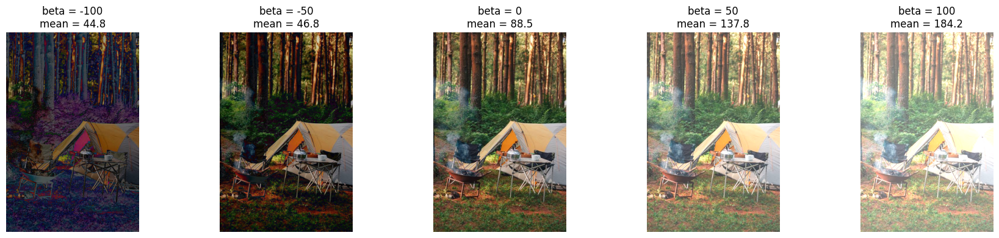

,Beta,Mean Image Intensity
0,-100,44.77
1,-50,46.79
2,0,88.46
3,50,137.83
4,100,184.19


In [86]:
img = images[list(images.keys())[0]]
betas = [-100, -50, 0, 50, 100]

plt.figure(figsize=(18, 4))
bright_rows = []

for i, beta in enumerate(betas, start=1):
    result = cv2.convertScaleAbs(img, alpha=1.0, beta=beta)
    mean_val = np.mean(result)
    print(f"Beta = {beta:4d} -> Mean intensity = {mean_val:.2f}")
    bright_rows.append((beta, round(mean_val, 2)))

    plt.subplot(1, 5, i)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"beta = {beta}\nmean = {mean_val:.1f}")
    plt.axis("off")

plt.tight_layout()
plt.show()

bright_df = pd.DataFrame(bright_rows, columns=["Beta", "Mean Image Intensity"])
display(bright_df)

In [87]:
for beta in [-100, 0, 100]:
    result = cv2.convertScaleAbs(img, alpha=1.0, beta=beta)
    print(f"beta = {beta:4d} -> pixels at 255: {np.mean(result == 255)*100:.2f}% | pixels at 0: {np.mean(result == 0)*100:.2f}%")

beta = -100 -> pixels at 255: 0.00% | pixels at 0: 0.53%
beta =    0 -> pixels at 255: 0.16% | pixels at 0: 0.13%
beta =  100 -> pixels at 255: 12.93% | pixels at 0: 0.00%


## Q66. What happens to pixel values when an image becomes extremely bright?
Pixel values rise toward the maximum of 255. Once a value would exceed 255 it is clipped (saturated) at 255, so many bright pixels become pure white. Different original intensities then end up with the same value, which means detail in highlights is permanently lost. The image looks washed out and the histogram piles up at the right end.

## Q67. How does beta affect brightness?
Beta is an additive offset applied to every pixel. A positive beta adds a constant to all pixel values and makes the image brighter, while a negative beta subtracts a constant and makes it darker. Because the same amount is added everywhere, the differences between pixels stay the same, so beta shifts the whole intensity range up or down without changing contrast, apart from the loss caused by clipping.

#**Task 14: Basic Contrast Manipulation**

Alpha = 0.5 -> Mean = 44.23 | Std dev (gray) = 23.80 | Min = 0 | Max = 127
Alpha = 0.8 -> Mean = 70.77 | Std dev (gray) = 38.08 | Min = 0 | Max = 203
Alpha = 1.0 -> Mean = 88.46 | Std dev (gray) = 47.60 | Min = 0 | Max = 254
Alpha = 1.5 -> Mean = 128.75 | Std dev (gray) = 63.30 | Min = 0 | Max = 255
Alpha = 2.0 -> Mean = 159.03 | Std dev (gray) = 64.27 | Min = 0 | Max = 255


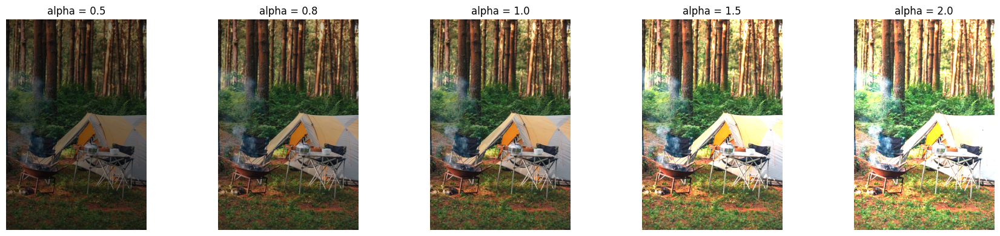

In [88]:
img = images[list(images.keys())[0]]
alphas = [0.5, 0.8, 1.0, 1.5, 2.0]

plt.figure(figsize=(18, 4))

for i, alpha in enumerate(alphas, start=1):
    result = cv2.convertScaleAbs(img, alpha=alpha, beta=0)
    gray_r = cv2.cvtColor(result, cv2.COLOR_BGR2GRAY)
    print(f"Alpha = {alpha:.1f} -> Mean = {np.mean(result):.2f} | Std dev (gray) = {np.std(gray_r):.2f} | Min = {gray_r.min()} | Max = {gray_r.max()}")

    plt.subplot(1, 5, i)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"alpha = {alpha}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Q71. Explain the difference between changing brightness and changing contrast.
Brightness is changed by adding or subtracting a constant (beta) from every pixel, which shifts all values up or down by the same amount and leaves the spacing between them the same. Contrast is changed by multiplying pixels by a factor (alpha), which stretches or compresses the spacing between dark and bright values. Alpha above 1 increases the difference between light and dark areas and alpha below 1 reduces it. In the formula output = alpha * pixel + beta, beta controls brightness and alpha controls contrast.

#**Task 15: Computing Basic Image Statistics**

In [89]:
selected = list(images.keys())[:3]
stats_rows = []

for i, name in enumerate(selected, start=1):
    gray = cv2.cvtColor(images[name], cv2.COLOR_BGR2GRAY)

    minimum = np.min(gray)
    maximum = np.max(gray)
    mean = np.mean(gray)
    median = np.median(gray)
    std = np.std(gray)

    print(f"--- Image {i}: {name} ---")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Mean:", mean)
    print("Median:", median)
    print("Standard deviation:", std)
    print()

    stats_rows.append((f"Image {i} ({name})", int(minimum), int(maximum),
                       round(mean, 2), round(float(median), 2), round(std, 2)))

stats_df = pd.DataFrame(stats_rows, columns=["Image", "Minimum", "Maximum", "Mean", "Median", "Std. Dev."])
display(stats_df)

--- Image 1: outdoor.jpeg ---
Minimum: 0
Maximum: 254
Mean: 93.88853864828883
Median: 83.0
Standard deviation: 47.601687126882865

--- Image 2: car.jpeg ---
Minimum: 0
Maximum: 255
Mean: 78.52551426632208
Median: 69.0
Standard deviation: 60.41222601687544

--- Image 3: person.jpeg ---
Minimum: 0
Maximum: 255
Mean: 75.08312550521752
Median: 61.0
Standard deviation: 56.98004493721574



,Image,Minimum,Maximum,Mean,Median,Std. Dev.
0,Image 1 (outdoor.jpeg),0,254,93.89,83.0,47.60
1,Image 2 (car.jpeg),0,255,78.53,69.0,60.41
2,Image 3 (person.jpeg),0,255,75.08,61.0,56.98


Brightest image (highest mean): Image 1 (outdoor.jpeg)
Greatest variation (highest std): Image 2 (car.jpeg)


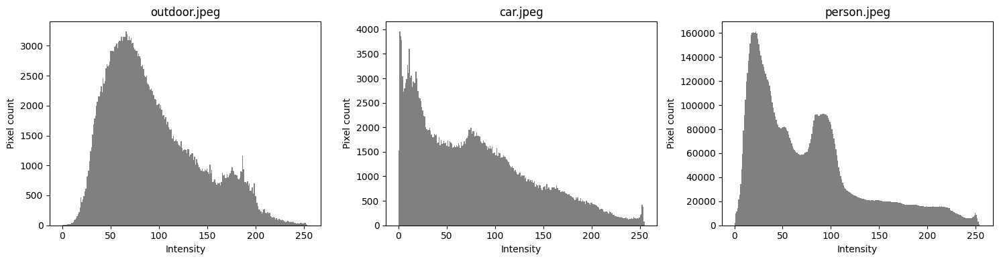

In [90]:
brightest = stats_df.loc[stats_df["Mean"].idxmax(), "Image"]
most_varied = stats_df.loc[stats_df["Std. Dev."].idxmax(), "Image"]
print("Brightest image (highest mean):", brightest)
print("Greatest variation (highest std):", most_varied)

plt.figure(figsize=(15, 4))
for i, name in enumerate(selected, start=1):
    gray = cv2.cvtColor(images[name], cv2.COLOR_BGR2GRAY)
    plt.subplot(1, 3, i)
    plt.hist(gray.ravel(), bins=256, range=(0, 255), color="gray")
    plt.title(f"{name}")
    plt.xlabel("Intensity")
    plt.ylabel("Pixel count")
plt.tight_layout()
plt.show()

## Q75. Which image is brightest according to mean intensity?
It is the image with the highest value in the Mean column of your table. Write it as: "[Image name] is the brightest, with a mean intensity of [value]."

## Q76. Which image shows the greatest variation in intensity values?
It is the image with the highest standard deviation. Write it as: "[Image name] shows the greatest variation, with a standard deviation of [value]."

## Q77. What does a high standard deviation approximately indicate?
A high standard deviation means pixel intensities are spread widely around the mean, so the image contains both very dark and very bright areas. This usually means high contrast and often more texture or detail. A low standard deviation means most pixels have similar values, as in a flat, foggy, evenly lit or low-contrast image.

#**Task 16: Comparing Color and Grayscale Memory Usage**

In [91]:
name = list(images.keys())[0]
img = images[name]
print("Selected image:", name, "| Shape:", img.shape)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print("Color image memory:", img.nbytes, "bytes")
print("Grayscale memory:", gray.nbytes, "bytes")

saving = img.nbytes - gray.nbytes
percentage = (saving / img.nbytes) * 100

print("Absolute reduction:", saving, "bytes")
print("Memory reduction:", round(percentage, 2), "%")

# Same numbers in more readable units
print(f"Color: {img.nbytes / (1024**2):.2f} MB | Grayscale: {gray.nbytes / (1024**2):.2f} MB | Saved: {saving / (1024**2):.2f} MB")

Selected image: outdoor.jpeg | Shape: (678, 452, 3)
Color image memory: 919368 bytes
Grayscale memory: 306456 bytes
Absolute reduction: 612912 bytes
Memory reduction: 66.67 %
Color: 0.88 MB | Grayscale: 0.29 MB | Saved: 0.58 MB


##Q81. Why is the grayscale array smaller?
A color image stores three values per pixel (B, G, R), while a grayscale image stores only one intensity value. With the same height, width and uint8 data type (1 byte per value), the grayscale array has H × W elements against H × W × 3 for the color image, so it uses one third of the memory.

##Q82. What information is lost during grayscale conversion?
All color (hue and saturation) information is lost. Only the brightness of each pixel remains, computed as a weighted combination of the three channels. Different colors with the same brightness, such as a red and a green object, can become the same gray value and can no longer be told apart. The conversion cannot be reversed to recover the original colors.

##Q83. Name a computer vision task where grayscale may be sufficient.
Edge detection is one example. Others include face detection with Haar cascades, optical character recognition (OCR), barcode and QR code reading, and many feature-matching tasks. In these, structure and intensity changes matter more than color, and working with one channel is faster and uses less memory.

#**Task 17: Image Format Experiment**

In [92]:
name = list(images.keys())[0]
img = images[name]
print("Source image:", name, "| Shape:", img.shape)

outputs = ["Lab01/output_images/output.jpg",
           "Lab01/output_images/output.png",
           "Lab01/output_images/output.bmp"]

for path in outputs:
    ok = cv2.imwrite(path, img)
    print(f"Saved {path}: {ok}")

size_rows = []
for path in outputs:
    size_bytes = os.path.getsize(path)
    fmt = path.split(".")[-1].upper()
    size_rows.append((fmt, size_bytes, round(size_bytes / 1024, 2), round(size_bytes / (1024**2), 3)))

size_df = pd.DataFrame(size_rows, columns=["Format", "Size (bytes)", "Size (KB)", "Size (MB)"])
display(size_df)

print("Smallest file:", size_df.loc[size_df["Size (bytes)"].idxmin(), "Format"])
print("Largest file :", size_df.loc[size_df["Size (bytes)"].idxmax(), "Format"])

Source image: outdoor.jpeg | Shape: (678, 452, 3)
Saved Lab01/output_images/output.jpg: True
Saved Lab01/output_images/output.png: True
Saved Lab01/output_images/output.bmp: True


,Format,Size (bytes),Size (KB),Size (MB)
0,JPG,145865,142.45,0.139
1,PNG,696749,680.42,0.664
2,BMP,919422,897.87,0.877


Smallest file: JPG
Largest file : BMP


JPG: max pixel difference vs original = 20
PNG: max pixel difference vs original = 0
BMP: max pixel difference vs original = 0


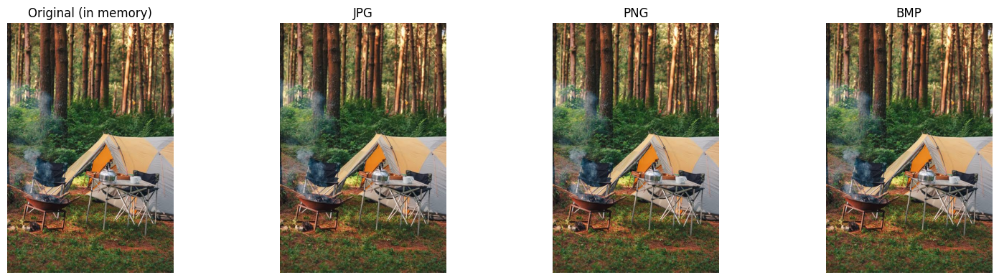

In [93]:
plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original (in memory)")
plt.axis("off")

for i, path in enumerate(outputs, start=2):
    reloaded = cv2.imread(path)
    diff = np.abs(img.astype(np.int16) - reloaded.astype(np.int16)).max()
    print(f"{path.split('.')[-1].upper()}: max pixel difference vs original = {diff}")
    plt.subplot(1, 4, i)
    plt.imshow(cv2.cvtColor(reloaded, cv2.COLOR_BGR2RGB))
    plt.title(path.split(".")[-1].upper())
    plt.axis("off")

plt.tight_layout()
plt.show()

##Q87. Which file is smallest?
Normally the JPG file, because JPEG uses lossy compression that removes information the eye is less sensitive to. Confirm with your own output.

##Q88. Which file is largest?
Normally the BMP file, because it stores raw uncompressed pixel data. Confirm with your own output.

##Q89. Why can image format selection matter in a computer vision project?
Lossy formats such as JPEG add compression artifacts and change pixel values, which can affect feature extraction, edge detection and model accuracy, especially for small details or medical images. Lossless formats such as PNG and BMP preserve exact pixel values but need more storage and bandwidth. Format choice also affects dataset size, loading speed, transmission over networks, and support for features such as transparency. A project therefore has to balance accuracy, storage and speed, for example using PNG for training data where accuracy matters and JPG for large-scale web images.

#**Task 18: Build a Basic Image Information Tool**

In [94]:
def analyze_image(path):
    # 1. Load and validate
    img = cv2.imread(path)
    if img is None:
        print("Could not load:", path)
        return None

    print("=" * 50)
    print("Analyzing:", path)
    print("=" * 50)

    # 2. Basic conversions
    h, w, c = img.shape
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    b, g, r = cv2.split(img)

    # 3. Print properties and statistics
    print("Width:", w)
    print("Height:", h)
    print("Channels:", c)
    print("Data type:", img.dtype)
    print("Total elements:", img.size)
    print("Min intensity:", np.min(gray))
    print("Max intensity:", np.max(gray))
    print("Mean intensity:", round(float(np.mean(gray)), 2))
    print("Std deviation:", round(float(np.std(gray)), 2))
    print("Mean B/G/R:", round(float(np.mean(b)), 2), round(float(np.mean(g)), 2), round(float(np.mean(r)), 2))

    # 4. ROI: central region (middle 50% of height and width)
    y1, y2 = h // 4, 3 * h // 4
    x1, x2 = w // 4, 3 * w // 4
    roi = img[y1:y2, x1:x2]

    # 5. Display original, grayscale and ROI
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
    plt.title(f"ROI (center) {roi.shape[1]}x{roi.shape[0]}")
    plt.axis("off")
    plt.show()

    # 6. Save grayscale result with a name based on the input file
    base = os.path.splitext(os.path.basename(path))[0]
    out_path = f"Lab01/output_images/{base}_gray.jpg"
    cv2.imwrite(out_path, gray)
    print("Saved grayscale image to:", out_path)

    return img

Analyzing: Lab01/input_images/outdoor.jpeg
Width: 452
Height: 678
Channels: 3
Data type: uint8
Total elements: 919368
Min intensity: 0
Max intensity: 254
Mean intensity: 93.89
Std deviation: 47.6
Mean B/G/R: 67.63 93.92 103.83


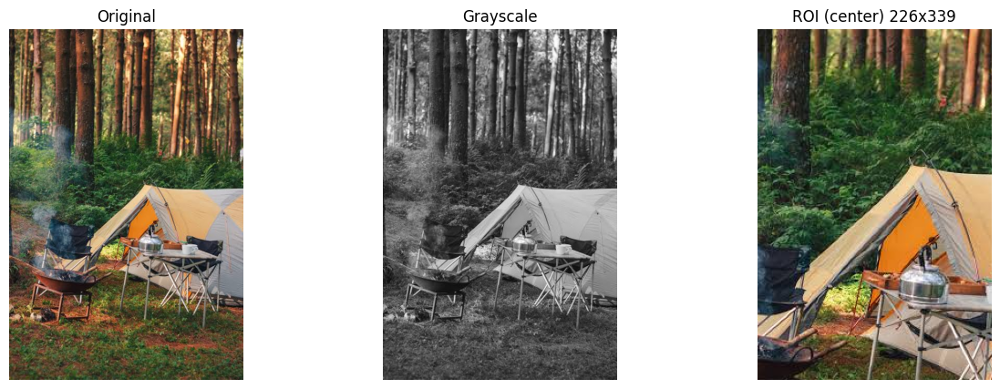

Saved grayscale image to: Lab01/output_images/outdoor_gray.jpg
Analyzing: Lab01/input_images/car.jpeg
Width: 678
Height: 452
Channels: 3
Data type: uint8
Total elements: 919368
Min intensity: 0
Max intensity: 255
Mean intensity: 78.53
Std deviation: 60.41
Mean B/G/R: 72.71 80.29 77.27


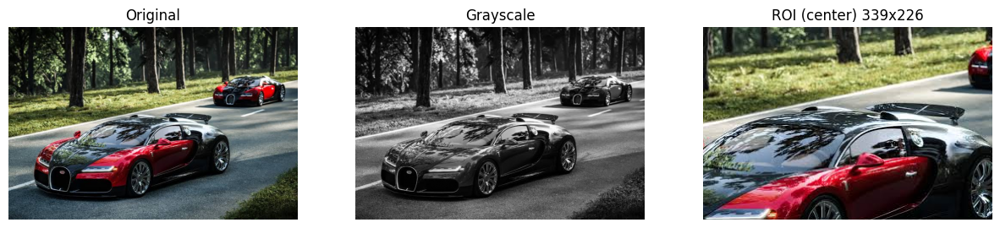

Saved grayscale image to: Lab01/output_images/car_gray.jpg
Analyzing: Lab01/input_images/person.jpeg
Width: 3024
Height: 4032
Channels: 3
Data type: uint8
Total elements: 36578304
Min intensity: 0
Max intensity: 255
Mean intensity: 75.08
Std deviation: 56.98
Mean B/G/R: 58.4 75.9 79.84


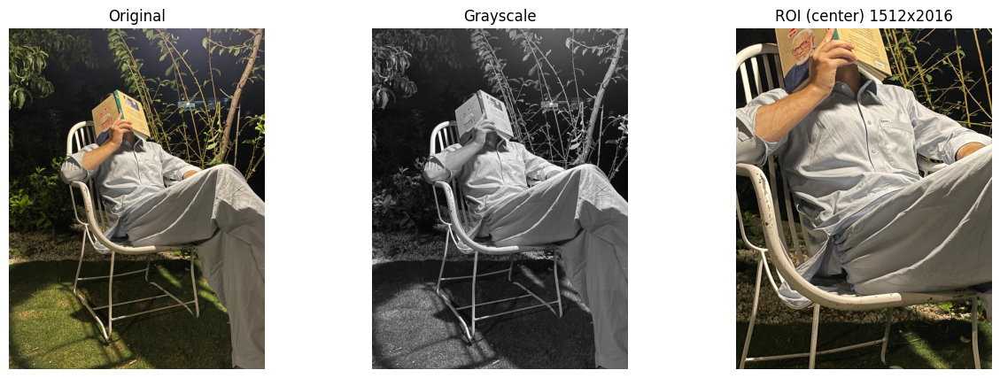

Saved grayscale image to: Lab01/output_images/person_gray.jpg


In [95]:
for name in list(images.keys())[:3]:
    analyze_image(f"Lab01/input_images/{name}")

In [96]:
analyze_image("Lab01/input_images/does_not_exist.jpg")   # should print "Could not load"

Could not load: Lab01/input_images/does_not_exist.jpg


In [97]:
print(os.listdir("Lab01/output_images"))

['output.bmp', 'output.png', 'person_gray.jpg', 'car_gray.jpg', '1_gray.jpg', 'outdoor_gray.jpg', 'output.jpg']


## Q97. Which parts of the function make it reusable for different images?

The image path is a parameter, so the same code works for any file.
Sizes and ROI positions are calculated from the image's own height and width and not hard-coded, so it works at any resolution.
Validation with if img is None makes it fail safely on bad paths instead of crashing.
The output filename is built from the input name, so results from different images don't overwrite each other.
It groups loading, conversion, statistics, display and saving into one call, so the whole analysis can be repeated in a loop.

#**Task 19: Mini Computer Vision Investigation**

In [98]:
import shutil
from google.colab import files

uploaded = files.upload()
for name in uploaded.keys():
    shutil.move(name, f"Lab01/input_images/{name}")
print(os.listdir("Lab01/input_images"))


Saving different.jpeg to different.jpeg
['outdoor.jpeg', 'car.jpeg', 'person.jpeg', 'Everyday.jpeg', 'indoor.jpeg', '2.jpeg', 'different.jpeg', '1.jpeg']


In [99]:
file_A = "1.jpeg"    # Updated to your uploaded filename
file_B = "2.jpeg"    # Updated to your uploaded filename

imgA = cv2.imread(f"Lab01/input_images/{file_A}")
imgB = cv2.imread(f"Lab01/input_images/{file_B}")

if imgA is None or imgB is None:
    print("Could not load one of the images, check the filenames.")
else:
    print("Both images loaded successfully. Shape A:", imgA.shape, "| Shape B:", imgB.shape)

Both images loaded successfully. Shape A: (4032, 3024, 3) | Shape B: (446, 686, 3)


In [100]:
# Load the correct uploaded filenames directly to avoid NoneType errors
imgA = cv2.imread("Lab01/input_images/1.jpeg")
imgB = cv2.imread("Lab01/input_images/2.jpeg")

def measure(img):
    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    b, g, r = cv2.split(img)
    return {
        "Width": w,
        "Height": h,
        "Mean intensity": round(float(np.mean(gray)), 2),
        "Standard deviation": round(float(np.std(gray)), 2),
        "Mean B": round(float(np.mean(b)), 2),
        "Mean G": round(float(np.mean(g)), 2),
        "Mean R": round(float(np.mean(r)), 2),
        "Memory usage (bytes)": img.nbytes,
    }

if imgA is None or imgB is None:
    print("Error: Could not load the images. Please verify '1.jpeg' and '2.jpeg' exist in Lab01/input_images.")
else:
    mA, mB = measure(imgA), measure(imgB)

    compare_df = pd.DataFrame({"Property": list(mA.keys()),
                               "Image A": list(mA.values()),
                               "Image B": list(mB.values())})
    compare_df["Difference (B - A)"] = compare_df["Image B"] - compare_df["Image A"]
    display(compare_df)

,Property,Image A,Image B,Difference (B - A)
0,Width,3024.00,686.00,-2338.00
1,Height,4032.00,446.00,-3586.00
2,Mean intensity,75.08,103.24,28.16
3,Standard deviation,56.98,58.45,1.47
4,Mean B,58.40,90.89,32.49
5,Mean G,75.90,105.56,29.66
6,Mean R,79.84,103.58,23.74
7,Memory usage (bytes),36578304.00,917868.00,-35660436.00


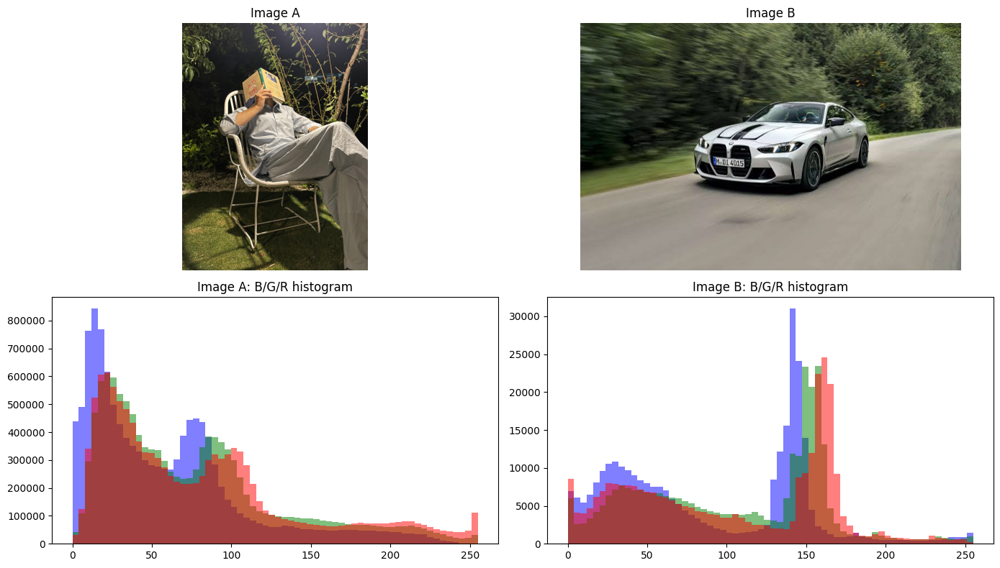

In [101]:
if imgA is None or imgB is None:
    print("Error: Cannot plot because Image A or Image B is None (not loaded).")
    print("Please update the filenames to match your uploaded files in Lab01/input_images/ (e.g., '1.jpeg' and '2.jpeg').")
else:
    plt.figure(figsize=(14, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(cv2.cvtColor(imgA, cv2.COLOR_BGR2RGB))
    plt.title("Image A")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(cv2.cvtColor(imgB, cv2.COLOR_BGR2RGB))
    plt.title("Image B")
    plt.axis("off")

    for i, (im, label) in enumerate([(imgA, "A"), (imgB, "B")], start=3):
        plt.subplot(2, 2, i)
        for ch, col in zip(cv2.split(im), ["blue", "green", "red"]):
            plt.hist(ch.ravel(), bins=64, range=(0, 255), color=col, alpha=0.5)
        plt.title(f"Image {label}: B/G/R histogram")

    plt.tight_layout()
    plt.show()

In [102]:
pct = ((compare_df["Image B"] - compare_df["Image A"]) / compare_df["Image A"]).abs() * 100
compare_df["% change"] = pct.round(2)
display(compare_df[["Property", "% change"]])
print("Largest change:", compare_df.loc[pct.idxmax(), "Property"])

,Property,% change
0,Width,77.31
1,Height,88.94
2,Mean intensity,37.51
3,Standard deviation,2.58
4,Mean B,55.63
5,Mean G,39.08
6,Mean R,29.73
7,Memory usage (bytes),97.49


Largest change: Memory usage (bytes)


Image A and Image B show the same scene, captured under [bright / dim lighting, or different viewpoints]. Both images have identical resolution ([W] x [H]) and memory usage ([bytes] bytes), because they were captured with the same device and settings, so acquisition conditions did not change the image size. The mean intensity changed from [A value] to [B value], showing that Image [A/B] is noticeably [brighter/darker]. The standard deviation changed from [A value] to [B value], which indicates that [contrast was higher/lower] in Image [A/B]. The mean B, G and R values also differ, with [channel] changing the most, which suggests a color shift caused by the [light source or white balance]. These measurements show that the digital values of an image depend strongly on lighting and capture conditions, even when the subject is exactly the same. Such differences can affect later computer vision steps such as thresholding, edge detection and object recognition, which is why acquisition conditions must be controlled or corrected.

##Q102. Which measured property changed the most between the two images?
Use the "Largest change" line from Cell 4. It is usually mean intensity or one of the channel means when the lighting differs. If the two photos were taken with different devices or crops, width, height and memory can change the most instead.

##Q103. How can acquisition conditions affect later computer vision algorithms?
Lighting, viewpoint, camera settings and noise change the pixel values that every later algorithm depends on. Thresholding and segmentation can fail when brightness shifts, edge detection finds different edges under shadows or low contrast, and color-based detection breaks when white balance changes the channel values. Recognition models trained on one kind of image can lose accuracy on images captured under different conditions. This is why systems use controlled lighting, normalization and data augmentation to reduce the effect.

#**Task 20: Final Challenge, Basic Image Processing Pipeline**

Image loaded successfully: Lab01/input_images/outdoor.jpeg


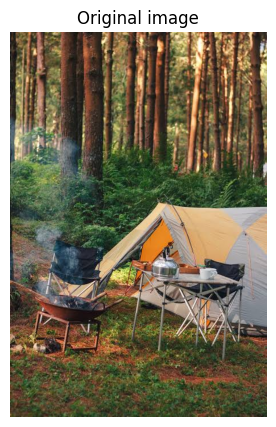

Height: 678
Width: 452
Channels: 3
Data type: uint8
Total elements: 919368
Memory usage: 919368 bytes
Mean B/G/R: 67.63 93.92 103.83
Gray min: 0 | max: 254
Gray mean: 93.89 | median: 83.0 | std: 47.6
ROI shape: (339, 226, 3)
Mean intensity -> original: 88.46 | bright: 147.45 | dark: 43.09


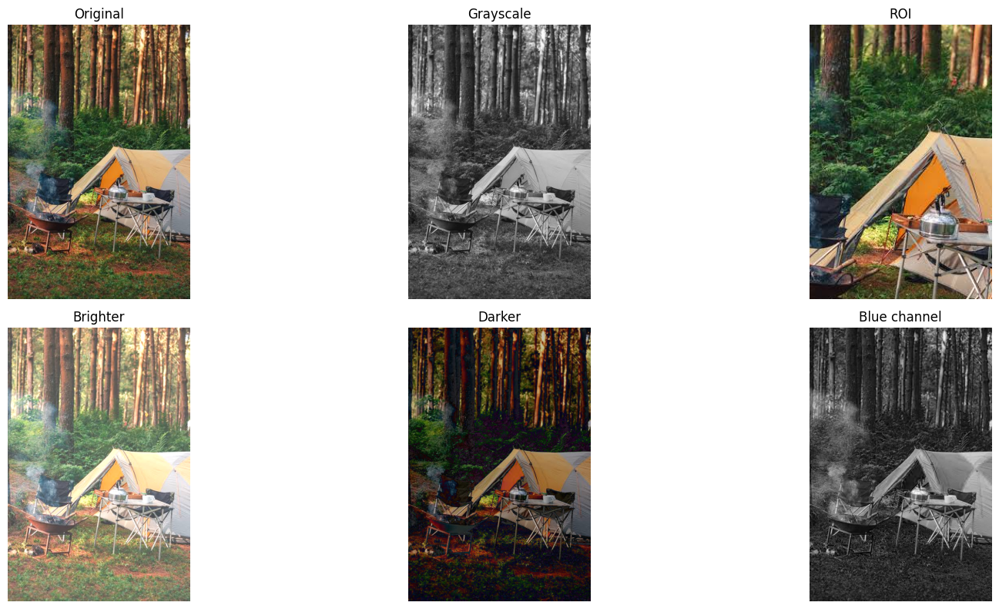

LAB 01 IMAGE PROCESSING COMPLETED
Original image size : 678 x 452 pixels, 919368 bytes
Image resolution    : 452 x 678 (306456 pixels)
Number of channels  : 3
Mean intensity      : 93.89
Files generated     : original_copy.jpg, rgb_image.jpg, grayscale.jpg, roi.jpg, bright.jpg, dark.jpg
Saved in folder     : Lab01_Output


In [103]:
def lab01_pipeline(input_path, output_dir="Lab01_Output"):
    # 1-2. Read and validate
    img = cv2.imread(input_path)
    if img is None:
        print("Could not load:", input_path)
        return
    print("Image loaded successfully:", input_path)

    os.makedirs(output_dir, exist_ok=True)
    generated = []

    def save(filename, image):
        path = os.path.join(output_dir, filename)
        cv2.imwrite(path, image)
        generated.append(filename)

    # 3. Display the original image
    plt.figure(figsize=(6, 5))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original image")
    plt.axis("off")
    plt.show()

    # 4. Print image properties
    h, w, c = img.shape
    print("Height:", h)
    print("Width:", w)
    print("Channels:", c)
    print("Data type:", img.dtype)
    print("Total elements:", img.size)
    print("Memory usage:", img.nbytes, "bytes")

    # 5. BGR to RGB
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 6. Grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 7. Split channels
    b, g, r = cv2.split(img)
    print("Mean B/G/R:", round(float(np.mean(b)), 2), round(float(np.mean(g)), 2), round(float(np.mean(r)), 2))

    # 8. Basic statistics (grayscale)
    mean_int = float(np.mean(gray))
    print("Gray min:", np.min(gray), "| max:", np.max(gray))
    print("Gray mean:", round(mean_int, 2), "| median:", np.median(gray), "| std:", round(float(np.std(gray)), 2))

    # 9. ROI (central region)
    roi = img[h // 4:3 * h // 4, w // 4:3 * w // 4]
    print("ROI shape:", roi.shape)

    # 10. Brighter and darker versions
    bright = cv2.convertScaleAbs(img, alpha=1.0, beta=60)
    dark = cv2.convertScaleAbs(img, alpha=1.0, beta=-60)
    print("Mean intensity -> original:", round(float(np.mean(img)), 2),
          "| bright:", round(float(np.mean(bright)), 2),
          "| dark:", round(float(np.mean(dark)), 2))

    # Display all results
    plt.figure(figsize=(18, 8))
    results = [("Original", rgb), ("Grayscale", gray), ("ROI", cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)),
               ("Brighter", cv2.cvtColor(bright, cv2.COLOR_BGR2RGB)),
               ("Darker", cv2.cvtColor(dark, cv2.COLOR_BGR2RGB)),
               ("Blue channel", b)]
    for i, (title, im) in enumerate(results, start=1):
        plt.subplot(2, 3, i)
        plt.imshow(im, cmap="gray" if im.ndim == 2 else None)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

    # 11. Save all outputs
    save("original_copy.jpg", img)
    save("rgb_image.jpg", rgb)      # saved as-is; looks color-swapped in viewers (see note below)
    save("grayscale.jpg", gray)
    save("roi.jpg", roi)
    save("bright.jpg", bright)
    save("dark.jpg", dark)

    # 12. Final summary
    print("========================================")
    print("LAB 01 IMAGE PROCESSING COMPLETED")
    print("========================================")
    print("Original image size :", f"{h} x {w} pixels,", f"{img.nbytes} bytes")
    print("Image resolution    :", f"{w} x {h}", f"({w * h} pixels)")
    print("Number of channels  :", c)
    print("Mean intensity      :", round(mean_int, 2))
    print("Files generated     :", ", ".join(generated))
    print("Saved in folder     :", output_dir)
    print("========================================")


lab01_pipeline("Lab01/input_images/" + list(images.keys())[0])

In [104]:
for f in sorted(os.listdir("Lab01_Output")):
    print(f, "-", os.path.getsize(f"Lab01_Output/{f}"), "bytes")

bright.jpg - 146437 bytes
dark.jpg - 161840 bytes
grayscale.jpg - 128857 bytes
original_copy.jpg - 145865 bytes
rgb_image.jpg - 144885 bytes
roi.jpg - 48206 bytes


In [105]:
import shutil
shutil.make_archive("Lab01_Output", "zip", "Lab01_Output")
from google.colab import files
files.download("Lab01_Output.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>